# METALYX — Notebook 1: B-spline-Only Feature Extraction and Classification

**Purpose:** Build a standalone geometric-feature baseline using Canny contours, cubic parametric B-splines, and a Logistic Regression classifier. This notebook does **not** load or use the SimCLR encoder.

## Workflow
1. Mount Google Drive and configure the NEU-DET folders.
2. Read the official train and validation image folders.
3. Inspect edge detection and B-spline contour fitting on a sample.
4. Extract 10 geometric features per image.
5. Save features **together with labels and image paths** so the integrated notebook can align rows safely.
6. Train a standardized Logistic Regression classifier and report accuracy, macro-F1, per-class metrics, and a confusion matrix.

**Important:** This uses the official validation split for evaluation. If you use these validation results to tune settings repeatedly, describe them as validation results—not as an untouched test result. Feature extraction can take several minutes.

## 1. Install/import dependencies

In [1]:
# If running in Google Colab, uncomment this line if a package is missing:
# %pip install opencv-python scipy scikit-learn tqdm seaborn

from pathlib import Path
import time
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.interpolate import splprep, splev
from tqdm.auto import tqdm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix
)

SEED = 42
np.random.seed(SEED)
print("OpenCV:", cv2.__version__)

OpenCV: 4.14.0


## 2. Mount Drive and set dataset paths

In [2]:
from google.colab import drive
drive.mount('/content/drive')

DATA_ROOT = Path('/content/drive/MyDrive/NEU-DET')
TRAIN_IMAGE_DIR = DATA_ROOT / 'train' / 'images'
VAL_IMAGE_DIR = DATA_ROOT / 'validation' / 'images'
OUTPUT_DIR = Path('/content/drive/MyDrive/METALYX/features')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    'crazing',
    'inclusion',
    'patches',
    'pitted_surface',
    'rolled-in_scale',
    'scratches'
]
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

for label, path in {
    'Training image directory': TRAIN_IMAGE_DIR,
    'Validation image directory': VAL_IMAGE_DIR,
}.items():
    print(f'{label}: {path} | exists={path.exists()}')

if not TRAIN_IMAGE_DIR.exists() or not VAL_IMAGE_DIR.exists():
    raise FileNotFoundError(
        "Dataset folders were not found. Update DATA_ROOT to match your Google Drive structure."
    )

Mounted at /content/drive
Training image directory: /content/drive/MyDrive/NEU-DET/train/images | exists=True
Validation image directory: /content/drive/MyDrive/NEU-DET/validation/images | exists=True


## 3. Index images and labels

In [3]:
def scan_class_folders(image_root, split_name):
    rows = []
    missing = []
    for class_name in CLASS_NAMES:
        class_dir = image_root / class_name
        if not class_dir.exists():
            missing.append(str(class_dir))
            continue
        for path in sorted(class_dir.rglob('*')):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTS:
                rows.append({
                    'image_path': str(path.resolve()),
                    'label': class_name,
                    'split': split_name
                })
    if missing:
        print("Missing class folders:")
        for path in missing:
            print(" -", path)
    return pd.DataFrame(rows)

train_df = scan_class_folders(TRAIN_IMAGE_DIR, 'train')
val_df = scan_class_folders(VAL_IMAGE_DIR, 'validation')

if train_df.empty or val_df.empty:
    raise ValueError("No images found. Check DATA_ROOT and class-folder layout.")

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
display(pd.DataFrame({
    'train': train_df['label'].value_counts().reindex(CLASS_NAMES, fill_value=0),
    'validation': val_df['label'].value_counts().reindex(CLASS_NAMES, fill_value=0)
}))
display(train_df.head())

Train images: 1440
Validation images: 360


,train,validation
label,,
crazing,240,60
inclusion,240,60
patches,240,60
pitted_surface,240,60
rolled-in_scale,240,60
scratches,240,60


,image_path,label,split
0,/content/drive/MyDrive/NEU-DET/train/images/cr...,crazing,train
1,/content/drive/MyDrive/NEU-DET/train/images/cr...,crazing,train
2,/content/drive/MyDrive/NEU-DET/train/images/cr...,crazing,train
3,/content/drive/MyDrive/NEU-DET/train/images/cr...,crazing,train
4,/content/drive/MyDrive/NEU-DET/train/images/cr...,crazing,train


## 4. Preview preprocessing and detected contours

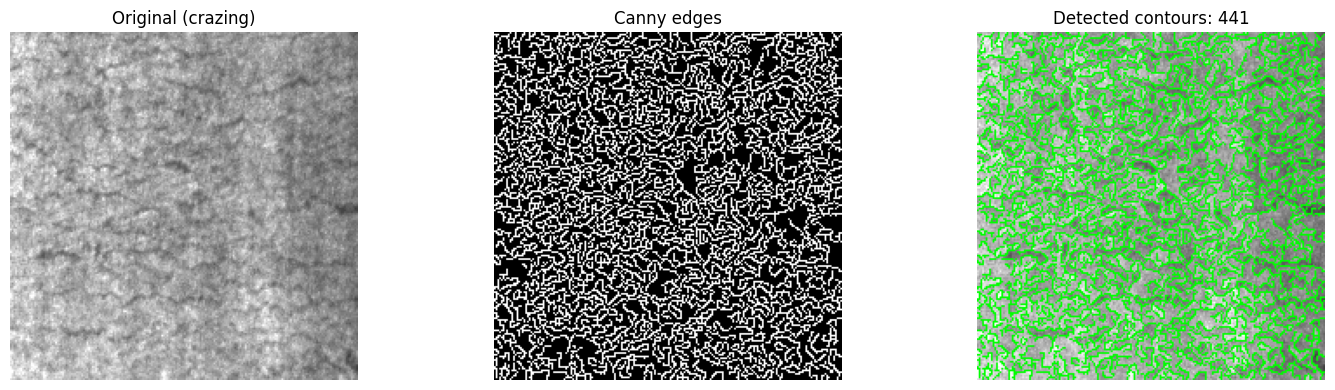

In [4]:
# Default is False to match the original B-spline feature-extraction notebook.
# Turn it on only if you intentionally want to test CLAHE as a changed preprocessing setting.
USE_CLAHE = False

def preprocess_for_edges(image_bgr, use_clahe=USE_CLAHE):
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    if use_clahe:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        gray = clahe.apply(gray)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    edges = cv2.Canny(gray, 40, 120)
    return gray, edges

sample = train_df.iloc[0]
sample_bgr = cv2.imread(sample['image_path'])
if sample_bgr is None:
    raise ValueError(f"Could not read sample image: {sample['image_path']}")
sample_gray, sample_edges = preprocess_for_edges(sample_bgr)
contours, _ = cv2.findContours(sample_edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
contour_overlay = sample_bgr.copy()
cv2.drawContours(contour_overlay, contours, -1, (0, 255, 0), 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(cv2.cvtColor(sample_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Original ({sample['label']})")
axes[1].imshow(sample_edges, cmap='gray')
axes[1].set_title("Canny edges")
axes[2].imshow(cv2.cvtColor(contour_overlay, cv2.COLOR_BGR2RGB))
axes[2].set_title(f"Detected contours: {len(contours)}")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Define the B-spline geometric features

For each image, the function:
- converts the image to grayscale (optionally applies CLAHE), smooths it, and detects edges;
- finds contours and fits a cubic parametric B-spline to eligible contours;
- estimates spline arc length, curvature, and direction changes;
- aggregates the 10 descriptors below across up to the 20 longest valid contours.

Curvature is numerically sensitive when spline derivatives are close to zero. The implementation guards the denominator and removes non-finite values. The feature vector is sanitized before returning.

In [5]:
FEATURE_NAMES = [
    "contour_count",
    "total_length",
    "largest_length",
    "mean_length",
    "total_area",
    "mean_area",
    "mean_abs_curvature",
    "max_abs_curvature",
    "curvature_std",
    "mean_direction_change"
]

def extract_bspline_features(image_path, use_clahe=USE_CLAHE):
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    if use_clahe:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        gray = clahe.apply(gray)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    edges = cv2.Canny(gray, 40, 120)

    contours, _ = cv2.findContours(
        edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE
    )
    measurements = []

    for contour in contours:
        points = contour.reshape(-1, 2).astype(np.float64)
        if len(points) < 10:
            continue

        # Remove consecutive duplicate points, which can destabilize splprep.
        keep = np.r_[True, np.any(np.diff(points, axis=0) != 0, axis=1)]
        points = points[keep]
        if len(points) < 4:
            continue

        try:
            tck, _ = splprep(
                [points[:, 0], points[:, 1]],
                s=max(1.0, len(points) * 0.05),
                k=3,
                per=False
            )
            u = np.linspace(0, 1, 100)
            x, y = map(np.asarray, splev(u, tck))
            dx, dy = map(np.asarray, splev(u, tck, der=1))
            ddx, ddy = map(np.asarray, splev(u, tck, der=2))

            speed_sq = dx**2 + dy**2
            denominator = np.maximum(speed_sq, 1e-8)**1.5
            curvature = np.abs(dx * ddy - dy * ddx) / denominator
            curvature = curvature[np.isfinite(curvature)]
            if curvature.size == 0:
                continue

            length = float(np.sum(np.hypot(np.diff(x), np.diff(y))))
            angles = np.unwrap(np.arctan2(np.diff(y), np.diff(x)))
            turns = np.abs(np.diff(angles))

            measurements.append({
                "length": length,
                "area": float(abs(cv2.contourArea(contour))),
                "mean_curvature": float(np.mean(curvature)),
                "max_curvature": float(np.max(curvature)),
                "curvature_std": float(np.std(curvature)),
                "direction": float(np.mean(turns)) if turns.size else 0.0
            })
        except (ValueError, TypeError, FloatingPointError, ZeroDivisionError):
            continue

    if not measurements:
        return np.zeros(len(FEATURE_NAMES), dtype=np.float32)

    measurements.sort(key=lambda item: item["length"], reverse=True)
    measurements = measurements[:20]

    lengths = np.asarray([m["length"] for m in measurements], dtype=np.float64)
    areas = np.asarray([m["area"] for m in measurements], dtype=np.float64)
    features = np.array([
        len(contours),
        lengths.sum(),
        lengths.max(),
        lengths.mean(),
        areas.sum(),
        areas.mean(),
        np.mean([m["mean_curvature"] for m in measurements]),
        max(m["max_curvature"] for m in measurements),
        np.mean([m["curvature_std"] for m in measurements]),
        np.mean([m["direction"] for m in measurements])
    ], dtype=np.float64)

    return np.nan_to_num(
        features, nan=0.0, posinf=0.0, neginf=0.0
    ).astype(np.float32)

print("Number of features:", len(FEATURE_NAMES))
print(FEATURE_NAMES)
print("Sample feature vector:")
print(extract_bspline_features(sample['image_path']))

Number of features: 10
['contour_count', 'total_length', 'largest_length', 'mean_length', 'total_area', 'mean_area', 'mean_abs_curvature', 'max_abs_curvature', 'curvature_std', 'mean_direction_change']
Sample feature vector:
[4.4100000e+02 7.0420557e+03 1.7580936e+03 3.5210278e+02 1.3292500e+04
 6.6462500e+02 1.3026335e+00 4.7134573e+02 6.3225245e+00 1.0501958e+00]


## 6. Extract features for train and validation images

In [6]:
# This is usually the longest step. Feature extraction is done once and saved below.
start = time.time()

def extract_split_features(frame, split_name):
    feature_rows = []
    failed = []
    for image_path in tqdm(frame['image_path'].tolist(), desc=f'{split_name} feature extraction'):
        try:
            feature_rows.append(extract_bspline_features(image_path))
        except Exception as exc:
            failed.append((image_path, repr(exc)))
            feature_rows.append(np.zeros(len(FEATURE_NAMES), dtype=np.float32))
    matrix = np.vstack(feature_rows).astype(np.float32)
    if failed:
        print(f"WARNING: {len(failed)} images failed; their rows were set to zeros.")
        print("First failures:", failed[:3])
    return matrix, failed

X_train_bspline, train_failures = extract_split_features(train_df, 'Train')
X_val_bspline, val_failures = extract_split_features(val_df, 'Validation')
y_train = train_df['label'].to_numpy()
y_val = val_df['label'].to_numpy()
train_paths = train_df['image_path'].to_numpy()
val_paths = val_df['image_path'].to_numpy()

print("Train feature shape:", X_train_bspline.shape)
print("Validation feature shape:", X_val_bspline.shape)
print(f"Elapsed: {(time.time() - start) / 60:.1f} minutes")
print("Finite train features:", np.isfinite(X_train_bspline).all())
print("Finite validation features:", np.isfinite(X_val_bspline).all())

Train feature extraction:   0%|          | 0/1440 [00:00<?, ?it/s]

Validation feature extraction:   0%|          | 0/360 [00:00<?, ?it/s]

Train feature shape: (1440, 10)
Validation feature shape: (360, 10)
Elapsed: 27.3 minutes
Finite train features: True
Finite validation features: True


## 7. Save features, labels, feature names, and paths

In [8]:

FEATURE_FILE = OUTPUT_DIR / 'bspline_features.npz'

# Convert labels and paths to regular string arrays
y_train_save = np.asarray(y_train, dtype=str)
y_val_save = np.asarray(y_val, dtype=str)
train_paths_save = np.asarray(train_paths, dtype=str)
val_paths_save = np.asarray(val_paths, dtype=str)

np.savez_compressed(
    FEATURE_FILE,
    X_train=np.asarray(X_train_bspline, dtype=np.float32),
    y_train=y_train_save,
    train_paths=train_paths_save,
    X_val=np.asarray(X_val_bspline, dtype=np.float32),
    y_val=y_val_save,
    val_paths=val_paths_save,
    feature_names=np.asarray(FEATURE_NAMES, dtype=str),
    class_names=np.asarray(CLASS_NAMES, dtype=str),
    use_clahe=np.asarray(USE_CLAHE, dtype=bool)
)

print("Saved:", FEATURE_FILE)
print("Train paths saved:", len(train_paths_save))
print("Validation paths saved:", len(val_paths_save))

# Verify the saved file
with np.load(FEATURE_FILE, allow_pickle=False) as data:
    assert data['X_train'].shape[0] == len(data['y_train']) == len(data['train_paths'])
    assert data['X_val'].shape[0] == len(data['y_val']) == len(data['val_paths'])
    assert data['X_train'].shape[1] == len(data['feature_names'])
    assert data['X_val'].shape[1] == len(data['feature_names'])

    print("Train feature shape:", data['X_train'].shape)
    print("Validation feature shape:", data['X_val'].shape)
    print("Train labels:", len(data['y_train']))
    print("Validation labels:", len(data['y_val']))
    print("Verification successful!")


Saved: /content/drive/MyDrive/METALYX/features/bspline_features.npz
Train paths saved: 1440
Validation paths saved: 360
Train feature shape: (1440, 10)
Validation feature shape: (360, 10)
Train labels: 1440
Validation labels: 360
Verification successful!


## 8. Train B-spline-only classifier

In [9]:
# Same classifier settings should be used in the integrated comparison notebook.
bspline_classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=3000,
        class_weight='balanced',
        random_state=SEED
    )
)

bspline_classifier.fit(X_train_bspline, y_train)
val_pred = bspline_classifier.predict(X_val_bspline)

accuracy = accuracy_score(y_val, val_pred)
macro_f1 = f1_score(y_val, val_pred, average='macro')

print(f"B-spline-only validation accuracy: {accuracy:.4%}")
print(f"B-spline-only validation macro-F1: {macro_f1:.4%}")
print()
print(classification_report(
    y_val, val_pred, labels=CLASS_NAMES, target_names=CLASS_NAMES,
    digits=4, zero_division=0
))

B-spline-only validation accuracy: 73.8889%
B-spline-only validation macro-F1: 72.1016%

                 precision    recall  f1-score   support

        crazing     0.7125    0.9500    0.8143        60
      inclusion     0.8548    0.8833    0.8689        60
        patches     0.6964    0.6500    0.6724        60
 pitted_surface     0.4571    0.2667    0.3368        60
rolled-in_scale     0.7258    0.7500    0.7377        60
      scratches     0.8615    0.9333    0.8960        60

       accuracy                         0.7389       360
      macro avg     0.7180    0.7389    0.7210       360
   weighted avg     0.7180    0.7389    0.7210       360



## 9. Confusion matrix

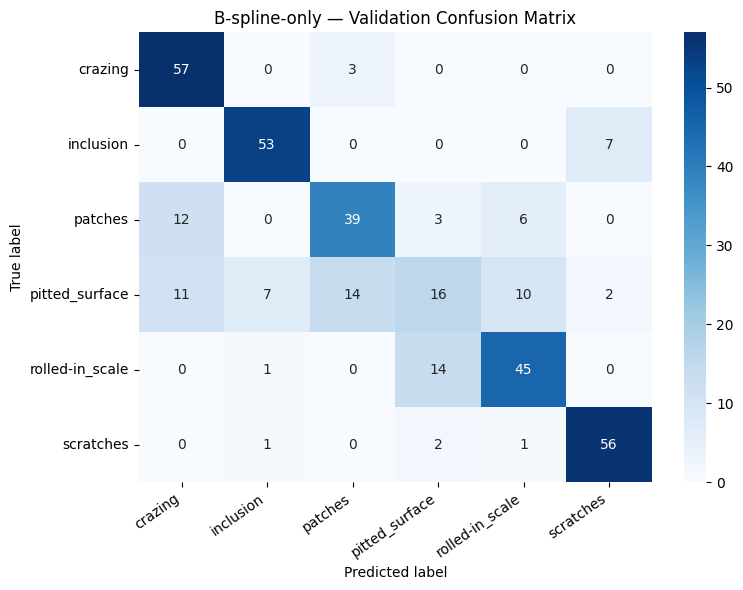

In [10]:
cm = confusion_matrix(y_val, val_pred, labels=CLASS_NAMES)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('B-spline-only — Validation Confusion Matrix')
plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Export predictions and summary metrics

In [11]:
predictions_file = OUTPUT_DIR / 'bspline_validation_predictions.csv'
pred_df = pd.DataFrame({
    'image_path': val_paths,
    'true_label': y_val,
    'predicted_label': val_pred,
    'correct': (y_val == val_pred)
})
pred_df.to_csv(predictions_file, index=False)

summary_file = OUTPUT_DIR / 'bspline_validation_metrics.csv'
summary_df = pd.DataFrame([{
    'method': 'B-spline-only',
    'validation_count': len(y_val),
    'accuracy': accuracy,
    'macro_f1': macro_f1,
    'feature_count': len(FEATURE_NAMES),
    'use_clahe': USE_CLAHE
}])
summary_df.to_csv(summary_file, index=False)

print("Saved predictions:", predictions_file)
print("Saved metrics:", summary_file)
display(summary_df)

Saved predictions: /content/drive/MyDrive/METALYX/features/bspline_validation_predictions.csv
Saved metrics: /content/drive/MyDrive/METALYX/features/bspline_validation_metrics.csv


,method,validation_count,accuracy,macro_f1,feature_count,use_clahe
0,B-spline-only,360,0.738889,0.721016,10,False


## Notes for the integrated notebook

- Load `bspline_features.npz` from the path printed in Section 7.
- Match each feature row to its image using `train_paths` and `val_paths`; **do not assume row order matches another notebook's image listing**.
- Keep the same official split and classifier settings when comparing B-spline-only, SimCLR-only, and fused features.
- `USE_CLAHE=False` preserves the original edge-preprocessing setup. If you switch it to `True`, rerun extraction and record that change in your report.
- This notebook currently defines **10 features**, matching the source B-spline extraction notebook—not 11.